In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from pathlib import Path
import xcdat as xc
import cmasher as cmr
import xarray as xr
import sys

sys.path.append('../../functions/')
from lag_linregress import *
from monthly_departures import *
from MCA import *

# Reload edited Python modules automatically before running subsequent cells.
%load_ext autoreload
%autoreload 2

import sys

# Add the project folder only once, even if this cell is rerun.
functions_path = "/scratch/leiff/MCA/amip_clean/project_functions/"
if functions_path not in sys.path:
    sys.path.append(functions_path)

from MCA_cov import *
from significance import *
from plotting import *
from diagnostics import *
# from taylor_setup import *
from setup_diagnostic import *

In [2]:
# 1. Imports and settings
from pathlib import Path
from copy import deepcopy
from datetime import datetime, timezone
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# These are HPC paths. Change archive_dir only if you have copied the archive.
# No raw climate data, new detrending, or existing model/MMM aggregates are used.
archive_dir = Path('/scratch/leiff/MCA/amip_clean/data/maps_2000_2014_covImp/overlap_core_200003_201412')
results_dir = archive_dir / 'diagnostic_steps_1_3' / 'run_01'
models_to_use = None                    # None = the AMIP/historical model intersection.
identity_rtol, identity_atol = 2e-5, 1e-8
save_results, load_results, overwrite = False, False, False

# Use an override ONLY after verifying the exact archive-axis order from source
# provenance. Never infer CMIP member labels from integer positions or counts.
# Example: {('historical', 'CanESM5'): {'labels': [...], 'evidence': 'file + check'}}
member_label_overrides = {}

# Figure choices. All row limits are shared across the three dataset columns.
plot_method, color_binning = 'pcolormesh', 'discrete'
cmap_name, central_longitude = 'cmr.fusion_r', 210
show_regions, show_stippling, save_figures = True, True, False
fdr_q, sign_threshold = 0.05, 0.80
figure_dpi = 200

In [3]:
# 2. Load the member archive and inspect its metadata
# Load only trusted pickle-containing files. The old model/MMM summaries and
# vs_obs scores are deliberately not loaded: their CanESM5 selection may be old.
archive_names = ['overlap_member_values', 'overlap_observations', 'overlap_coordinates',
                 'overlap_model_names', 'overlap_member_ids', 'overlap_quantity_info',
                 'overlap_sources', 'overlap_metadata']
missing_files = [name + '.npy' for name in archive_names if not (archive_dir / (name + '.npy')).exists()]
if missing_files:
    raise FileNotFoundError(f'Archive not available at {archive_dir}. Missing: {missing_files}')
archive = {name: np.load(archive_dir / (name + '.npy'), allow_pickle=True).item() for name in archive_names}
source_values = archive['overlap_member_values']
source_observations = archive['overlap_observations']
source_coordinates = archive['overlap_coordinates']
source_model_names = archive['overlap_model_names']
source_member_ids = archive['overlap_member_ids']
source_metadata = archive['overlap_metadata']
historical_source = 'historical' if 'historical' in source_values else 'historical_matched'
print('Archive:', archive_dir)
print('Registered quantities:', list(archive['overlap_quantity_info']))
display(pd.Series(source_metadata, name='saved setting').to_frame())
print('Radiation sign and units are preserved from the input archive; no sign is flipped here.')
print('Intended N = rsdt - rsut - rlut, positive downward. Check raw metadata if its sign is unverified.')

Archive: /scratch/leiff/MCA/amip_clean/data/maps_2000_2014_covImp/overlap_core_200003_201412
Registered quantities: ['corr_Ti_Ri', 'corr_T_Ri', 'corr_Ti_R', 'corr_T_R', 'sigma_Ti', 'sigma_Ri', 'sigma_T', 'sigma_R', 'T_detrended', 'R_detrended', 'T_trend_in', 'R_trend_in', 'cov_Zi_R', 'cov_Ti_R', 'cov_T_Qi', 'cov_T_Ri', 'cov_Zi_Ri', 'cov_Ti_Qi', 'cov_Ti_Ri']


,saved setting
schema_version,1
created_utc,2026-09-11T21:55:18.708173+00:00
start_month,2000-03
end_month,2014-12
n_time,178
ddof,1
detrending_function,detrend_monthly_fast
detrending_source,"def detrend_monthly_fast(arr):\n """"""Detrend..."
preprocessing,User's monthwise detrend/deseasonalize; then c...
trend_in_series,Subtract each calendar month's mean within the...


Radiation sign and units are preserved from the input archive; no sign is flipped here.
Intended N = rsdt - rsut - rlut, positive downward. Check raw metadata if its sign is unverified.


In [14]:
# 3. Check dates, weights, support, and member labels; select CanESM5 p2
lat, lon = [np.asarray(source_coordinates[key], dtype=float) for key in ['lat', 'lon']]
times = np.asarray(source_coordinates['time']).astype('datetime64[M]')
expected_months = np.arange(np.datetime64('2000-03'), np.datetime64('2015-01'), dtype='datetime64[M]')
if not np.array_equal(times, expected_months):
    raise ValueError('This comparison requires exactly March 2000–December 2014 (178 months).')
if lat.ndim != 1 or lon.ndim != 1 or not np.isfinite(lat).all() or not np.isfinite(lon).all():
    raise ValueError('Expected finite 1-D coordinates.')
if not (np.all(np.diff(lat) > 0) and np.all(np.diff(lon) > 0)):
    raise ValueError('Coordinates must increase; reorder DATA and coordinates together upstream.')
grid_shape = (len(lat), len(lon))
base_weights, global_weights = [np.asarray(source_coordinates[key], dtype=float)
                                for key in ['base_weights', 'global_weights']]
local_support = np.asarray(source_coordinates['local_support'], dtype=bool)
for weights in [base_weights, global_weights]:
    if weights.shape != grid_shape or not np.isfinite(weights).all() or np.any(weights < 0):
        raise ValueError('Saved weights must be finite, nonnegative, and match the grid.')
    np.testing.assert_allclose(weights.sum(), 1., rtol=0, atol=1e-10)
if local_support.shape != grid_shape or not local_support.any():
    raise ValueError('Saved local_support must be a nonempty grid mask.')
if not np.allclose(global_weights, base_weights, rtol=0, atol=1e-12):
    raise ValueError('Saved indices use a restricted domain. They cannot be labelled global in these figures.')
ddof = source_metadata.get('ddof')
if not isinstance(ddof, (int, np.integer)) or not 0 <= ddof < len(times):
    raise ValueError('The archive must record its temporal ddof.')
if source_metadata.get('detrending_function') != 'detrend_monthly_fast':
    raise ValueError('This notebook requires recorded use of the user\'s detrend_monthly_fast.')
if source_metadata.get('n_time') != len(times):
    raise ValueError('The saved metadata and time coordinate disagree about sample count.')
print(f'Grid: {grid_shape}; months: {len(times)}; temporal ddof: {ddof}')
print('Preprocessing:', source_metadata.get('preprocessing', 'NOT RECORDED'))
print('Detrending source saved:', bool(source_metadata.get('detrending_source')))
print('The compact archive cannot independently recheck raw-field preprocessing or local SDs.')

# Match MODELS across experiments, keeping all selected members within each model.
# AMIP and historical member numbers are not synchronized realizations.
for group in ['amip_hist', historical_source]:
    names = list(source_model_names[group])
    if not names or len(names) != len(set(names)):
        raise ValueError(f'{group}: model labels are empty or duplicated.')
matched_models = [m for m in source_model_names['amip_hist'] if m in source_model_names[historical_source]]
if models_to_use is not None:
    if not models_to_use or len(models_to_use) != len(set(models_to_use)) or not set(models_to_use) <= set(matched_models):
        raise ValueError('models_to_use must be a nonempty, unique subset of the matched models.')
    matched_models = list(models_to_use)
if not matched_models:
    raise ValueError('No matched models remain.')
experiment_sources = {'historical_matched': historical_source, 'amip_hist': 'amip_hist'}
diagnostic_model_names = {exp: matched_models.copy() for exp in experiment_sources}
diagnostic_member_ids = {exp: {} for exp in experiment_sources}
member_selection, selection_rows = {exp: {} for exp in experiment_sources}, []
member_pattern = re.compile(r'r(\d+)i(\d+)p(\d+)f(\d+)')
for experiment, source in experiment_sources.items():
    for model in matched_models:
        archive_ids = np.asarray(source_member_ids[source][model])
        labels = np.array([x.decode() if isinstance(x, bytes) else str(x) for x in archive_ids])
        override = member_label_overrides.get((source, model))
        evidence = 'saved archive member labels'
        if override is not None:
            labels, evidence = np.asarray(override['labels'], dtype=str), override['evidence']
            if labels.shape != archive_ids.shape or not str(evidence).strip():
                raise ValueError('An override needs one verified label per archive member and provenance.')
        if labels.ndim != 1 or not len(labels) or len(set(labels)) != len(labels):
            raise ValueError(f'{source}/{model}: missing or duplicated member labels.')
        keep = np.ones(len(labels), dtype=bool)
        if model == 'CanESM5':
            parsed = [member_pattern.fullmatch(label) for label in labels]
            if any(match is None for match in parsed):
                raise ValueError('CanESM5 physics cannot be verified from these IDs. Supply an explicitly verified '
                                 'member_label_overrides entry, or regenerate labelled member diagnostics.')
            keep = np.array([int(match.group(3)) == 2 for match in parsed])
            if not keep.any():
                raise ValueError(f'{source}/CanESM5 has no p2 members. No p1 substitution is allowed.')
        member_selection[experiment][model] = np.flatnonzero(keep)
        diagnostic_member_ids[experiment][model] = labels[keep]
        selection_rows.append({'experiment': experiment, 'model': model, 'source_group': source,
                               'archive_members': len(labels), 'selected_members': int(keep.sum()),
                               'excluded_members': int((~keep).sum()), 'label_evidence': evidence,
                               'archive_ids': archive_ids.tolist(), 'selected_labels': labels[keep].tolist()})
selection_table = pd.DataFrame(selection_rows)
display(selection_table.drop(columns=['archive_ids', 'selected_labels']))

# Adopt the shared geographic definitions without imposing an ocean-only mask.
# These masks are saved for provenance; region outlines do not restrict scoring.
# import region_definitions as region_defs
# diagnostic_regions = {'version': region_defs.REGION_VERSION, 'definitions': deepcopy(region_defs.REGIONS),
#                       'masks': region_defs.make_region_masks(lat, lon),
#                       'vertices': {name: region_defs.region_vertices(name) for name in region_defs.REGIONS}}
diagnostic_coordinates = deepcopy(source_coordinates)
diagnostic_metadata = {'created_utc': datetime.now(timezone.utc).isoformat(), 'source_archive': str(archive_dir),
                       'source_metadata': deepcopy(source_metadata), 'source_quantity_info': deepcopy(archive['overlap_quantity_info']),
                       'source_provenance': deepcopy(archive['overlap_sources']), 'selection': selection_rows,
                       'physics_selection': 'CanESM5 p2 only; other models unchanged',
                       'aggregation': 'Arithmetic member means, then equal-model means; no Fisher-z',
                       'identity_rtol': identity_rtol, 'identity_atol': identity_atol,
                       'radiation_sign': 'Input sign preserved; downward-positive intended, not newly verified',
                       'region_version': diagnostic_regions['version']}

# Adopted geographic regions; longitudes are degrees east.
# These masks include land and do not restrict the scoring domain.
adopted_regions = {
    "SEP":  {"lat_range": (-35., -5.), "west": 250., "east_at_south": 290., "east_at_north": 280.},
    "NEP":  {"lat_range": (15., 38.),  "west": 218., "east_at_south": 255., "east_at_north": 235.},
    "WPWP": {"lat_range": (-10., 10.), "west": 80.,  "east_at_south": 150., "east_at_north": 150.},
}

# Select grid centers inside each region, allowing the eastern edge to taper.
latitude, longitude = lat[:, None], (lon % 360.)[None, :]
region_masks, region_outlines = {}, {}

for name, region in adopted_regions.items():
    south, north = region["lat_range"]
    west = region["west"]
    east_south, east_north = region["east_at_south"], region["east_at_north"]
    east_limit = east_south + (east_north - east_south) * (latitude - south) / (north - south)

    region_masks[name] = (
        (latitude >= south) & (latitude <= north)
        & (longitude >= west) & (longitude <= east_limit)
    )
    region_outlines[name] = np.array([
        [west, south], [east_south, south],
        [east_north, north], [west, north],
    ])

diagnostic_regions = {
    "version": "2026-10-27_SEP110W_NEP142W_WPWP-original",
    "definitions": deepcopy(adopted_regions),
    "masks": region_masks,
    "vertices": region_outlines,
    "definition_source": "Embedded snapshot of project region_definitions.py",
}

from pathlib import Path
from textwrap import dedent

region_file = Path("region_definitions.py")
if not region_file.exists():
    region_file.write_text(dedent(f"""\
        import numpy as np

        REGION_VERSION = {diagnostic_regions["version"]!r}
        REGIONS = {diagnostic_regions["definitions"]!r}

        def region_vertices(name):
            region = REGIONS[name]
            south, north = region["lat_range"]
            west = region["west"]
            return np.array([
                [west, south], [region["east_at_south"], south],
                [region["east_at_north"], north], [west, north],
            ])

        def make_region_masks(lat, lon):
            latitude = np.asarray(lat)[:, None]
            longitude = np.asarray(lon)[None, :] % 360.
            masks = {{}}
            for name, region in REGIONS.items():
                south, north = region["lat_range"]
                east = region["east_at_south"] + (
                    region["east_at_north"] - region["east_at_south"]
                ) * (latitude - south) / (north - south)
                masks[name] = (
                    (latitude >= south) & (latitude <= north)
                    & (longitude >= region["west"]) & (longitude <= east)
                )
            return masks
        """), encoding="utf-8")

Grid: (72, 144); months: 178; temporal ddof: 1
Preprocessing: User's monthwise detrend/deseasonalize; then center through time
Detrending source saved: True
The compact archive cannot independently recheck raw-field preprocessing or local SDs.


,experiment,model,source_group,archive_members,selected_members,excluded_members,label_evidence
0,historical_matched,BCC-CSM2-MR,historical,3,3,0,saved archive member labels
1,historical_matched,CAMS-CSM1-0,historical,3,3,0,saved archive member labels
2,historical_matched,CESM2,historical,11,11,0,saved archive member labels
3,historical_matched,CIESM,historical,3,3,0,saved archive member labels
4,historical_matched,CNRM-CM6-1,historical,29,29,0,saved archive member labels
5,historical_matched,CNRM-CM6-1-HR,historical,1,1,0,saved archive member labels
6,historical_matched,CNRM-ESM2-1,historical,10,10,0,saved archive member labels
7,historical_matched,CanESM5,historical,65,40,25,saved archive member labels
8,historical_matched,FGOALS-f3-L,historical,3,3,0,saved archive member labels
9,historical_matched,FGOALS-g3,historical,6,6,0,saved archive member labels


In [6]:
# 4. Reconstruct member diagnostics and check them against saved covariances
# All covariances and sigmas use the archive's same samples and temporal ddof.
# Temperature is tas/t2m, not prescribed SST. sigma_R is a global SERIES SD.
required_keys = ['corr_Ti_R', 'corr_Ti_Ri', 'sigma_Ti', 'sigma_Ri', 'sigma_T', 'sigma_R',
                 'T_detrended', 'R_detrended']
diagnostic_quantity_info = {
    'corr_Ti_R': {'kind': 'map', 'units': '1', 'definition': 'Corr(T_i, R_g)'},
    'corr_Ti_Ri': {'kind': 'map', 'units': '1', 'definition': 'Corr(T_i, R_i)'},
    'sigma_Ti': {'kind': 'map', 'units': 'K', 'definition': 'SD(T_i)'},
    'sigma_Ri': {'kind': 'map', 'units': 'W m-2', 'definition': 'SD(R_i)'},
    'sigma_T': {'kind': 'scalar', 'units': 'K', 'definition': 'SD(T_g)'},
    'sigma_R': {'kind': 'scalar', 'units': 'W m-2', 'definition': 'SD(R_g)'},
    'T_detrended': {'kind': 'series', 'units': 'K', 'definition': 'Processed global temperature'},
    'R_detrended': {'kind': 'series', 'units': 'W m-2', 'definition': 'Processed global net TOA radiation'},
    'cov_Ti_R': {'kind': 'map', 'units': 'K W m-2', 'definition': 'Cov(T_i, R_g)'},
    'cov_Ti_Ri': {'kind': 'map', 'units': 'K W m-2', 'definition': 'Cov(T_i, R_i)'},
    'cov_Zi_R': {'kind': 'map', 'units': 'W m-2', 'definition': 'Cov(T_i / SD(T_i), R_g)'},
    'cov_Zi_Ri': {'kind': 'map', 'units': 'W m-2', 'definition': 'Cov(T_i / SD(T_i), R_i)'},
}
identity_rows = []

def reconstruct_diagnostics(values, label):
    """One member or observation: input maps are (lat,lon), globals are scalars."""
    values = {key: np.asarray(value, dtype=float) for key, value in values.items()}
    for key in required_keys:
        if key not in values:
            raise KeyError(f'{label}: missing {key}')
        kind = diagnostic_quantity_info[key]['kind']
        expected = {'map': grid_shape, 'scalar': (), 'series': (len(times),)}[kind]
        if values[key].shape != expected:
            raise ValueError(f'{label}/{key}: expected {expected}, got {values[key].shape}')
    result = {key: values[key].copy() for key in required_keys}
    sTi, sRi, sT, sR = [values[key] for key in ['sigma_Ti', 'sigma_Ri', 'sigma_T', 'sigma_R']]
    for key in ['sigma_Ti', 'sigma_Ri', 'sigma_T', 'sigma_R']:
        if np.any(np.isfinite(values[key]) & (values[key] < 0)):
            raise ValueError(f'{label}: negative SD in {key}')
    for key in ['corr_Ti_R', 'corr_Ti_Ri']:
        if np.any(np.abs(values[key][np.isfinite(values[key])]) > 1 + identity_atol):
            raise ValueError(f'{label}: correlation outside [-1, 1]')

    # Raw covariance is zero for a finite constant variable, even when correlation
    # is undefined. A standardized constant TEMPERATURE predictor stays undefined.
    for suffix, rho, response_sd in [('R', values['corr_Ti_R'], sR),
                                      ('Ri', values['corr_Ti_Ri'], sRi)]:
        finite_sd = np.isfinite(sTi) & np.isfinite(response_sd)
        raw_cov = np.where(finite_sd & ((sTi == 0) | (response_sd == 0)), 0., rho * sTi * response_sd)
        standard_cov = np.divide(raw_cov, sTi, out=np.full(grid_shape, np.nan), where=sTi > 0)
        for key, reconstructed in [('cov_Ti_' + suffix, raw_cov), ('cov_Zi_' + suffix, standard_cov)]:
            reconstructed = np.where(local_support, reconstructed, np.nan)
            independently_saved = key in values
            if independently_saved:
                if values[key].shape != grid_shape:
                    raise ValueError(f'{label}/{key}: saved covariance must match the grid.')
                np.testing.assert_allclose(values[key], reconstructed, rtol=identity_rtol,
                                           atol=identity_atol, equal_nan=True, err_msg=f'{label}/{key}')
                finite = np.isfinite(values[key]) & np.isfinite(reconstructed)
                max_error = float(np.max(np.abs(values[key][finite] - reconstructed[finite]))) if finite.any() else np.nan
                result[key] = values[key].copy()
            else:
                max_error, result[key] = np.nan, reconstructed
            identity_rows.append({'dataset': label, 'quantity': key, 'independent_saved_check': independently_saved,
                                  'max_absolute_error': max_error,
                                  'note': 'saved covariance checked' if independently_saved else 'reconstructed only; no independent covariance saved'})

    # Unlike local maps, these global time series are retained. Check their SDs
    # directly and verify that processed series are centered within tolerance.
    for series_key, sigma_key in [('T_detrended', 'sigma_T'), ('R_detrended', 'sigma_R')]:
        series = values[series_key]
        if not np.isfinite(series).all():
            raise ValueError(f'{label}/{series_key}: missing months')
        np.testing.assert_allclose(series.std(ddof=ddof), values[sigma_key], rtol=identity_rtol, atol=identity_atol)
        np.testing.assert_allclose(series.mean(), 0., atol=identity_atol * max(1., float(values[sigma_key])))
    return result

diagnostic_observations = reconstruct_diagnostics(source_observations, 'observations')
diagnostic_member_values = {exp: {key: {} for key in diagnostic_quantity_info} for exp in experiment_sources}
for experiment, source in experiment_sources.items():
    for model in matched_models:
        selected = member_selection[experiment][model]
        available = source_values[source]
        n_archive = len(source_member_ids[source][model])
        member_inputs = {}
        for key in required_keys + ['cov_Ti_R', 'cov_Ti_Ri', 'cov_Zi_R', 'cov_Zi_Ri']:
            if key in available and model in available[key]:
                array = np.asarray(available[key][model], dtype=float)
                if array.shape[0] != n_archive:
                    raise ValueError(f'{source}/{model}/{key}: member axis does not match saved IDs.')
                member_inputs[key] = array[selected]
        calculated = []
        for index, member in enumerate(diagnostic_member_ids[experiment][model]):
            calculated.append(reconstruct_diagnostics({key: value[index] for key, value in member_inputs.items()},
                                                      f'{experiment}/{model}/{member}'))
        for key in diagnostic_quantity_info:
            diagnostic_member_values[experiment][key][model] = np.stack([value[key] for value in calculated])
identity_table = pd.DataFrame(identity_rows)
display(identity_table.groupby(['quantity', 'independent_saved_check'], dropna=False)['max_absolute_error'].agg(['count', 'max']))
print('Rows marked reconstructed only are algebraic constructions, not independent validation.')

,,count,max
quantity,independent_saved_check,,
cov_Ti_R,True,177,2.220446e-16
cov_Ti_Ri,True,177,7.105427e-15
cov_Zi_R,True,177,2.220446e-16
cov_Zi_Ri,True,177,7.105427e-15


Rows marked reconstructed only are algebraic constructions, not independent validation.


In [7]:
# 5. Recompute model means and equal-model MMMs after member selection
def mean_and_count(values):
    """Finite arithmetic mean over the first axis, with explicit contributor counts."""
    values = np.asarray(values, dtype=float)
    finite = np.isfinite(values)
    count, total = finite.sum(axis=0), np.where(finite, values, 0.).sum(axis=0)
    mean = np.divide(total, count, out=np.full_like(total, np.nan), where=count > 0)
    return mean, count

diagnostic_model_means, diagnostic_model_n_valid = {}, {}
diagnostic_MMM, diagnostic_MMM_n_valid = {}, {}
for experiment, models in diagnostic_model_names.items():
    diagnostic_model_means[experiment], diagnostic_model_n_valid[experiment] = {}, {}
    diagnostic_MMM[experiment], diagnostic_MMM_n_valid[experiment] = {}, {}
    for key in diagnostic_quantity_info:
        model_results = [mean_and_count(diagnostic_member_values[experiment][key][model]) for model in models]
        diagnostic_model_means[experiment][key] = np.stack([value[0] for value in model_results])
        diagnostic_model_n_valid[experiment][key] = np.stack([value[1] for value in model_results])
        diagnostic_MMM[experiment][key], diagnostic_MMM_n_valid[experiment][key] = mean_and_count(
            diagnostic_model_means[experiment][key])
print('Means rebuilt from selected members. MMM maps average diagnostics, not monthly ensemble-mean fields.')

Means rebuilt from selected members. MMM maps average diagnostics, not monthly ensemble-mean fields.


In [8]:
# Plotting function — shared row scales, adopted regions, and new robustness masks
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from matplotlib.colors import BoundaryNorm, Normalize
from scipy.stats import ttest_1samp
try:
    import cmasher                         # Registers the original cmr.fusion_r palette.
except ImportError:
    if cmap_name.startswith('cmr.'):
        cmap_name = 'RdBu_r'
        print('Cmasher is unavailable; using RdBu_r.')

def mean_and_count(values):
    """Finite arithmetic mean over the first axis, with explicit contributor counts."""
    values = np.asarray(values, dtype=float)
    finite = np.isfinite(values)
    count, total = finite.sum(axis=0), np.where(finite, values, 0.).sum(axis=0)
    mean = np.divide(total, count, out=np.full_like(total, np.nan), where=count > 0)
    return mean, count

def model_robustness(model_maps, *, q=0.05, agreement_threshold=0.80):
    """Original operational criterion: BH FDR AND >80% sign agreement with MMM."""
    model_maps = np.asarray(model_maps, dtype=float)
    mean_map, count = mean_and_count(model_maps)
    # The test samples MODEL MEANS, not members or 178 independent months.
    # Model dependence and unequal ensemble precision limit inferential meaning.
    pvalue = np.full(mean_map.shape, np.nan)
    eligible = count >= 2
    if eligible.any():
        pvalue[eligible] = ttest_1samp(model_maps[:, eligible], 0., axis=0, nan_policy='omit').pvalue
    adjusted = np.full(pvalue.shape, np.nan)
    flat = np.flatnonzero(np.isfinite(pvalue))
    if len(flat):
        ordered = flat[np.argsort(pvalue.ravel()[flat])]
        ranked = pvalue.ravel()[ordered] * len(ordered) / np.arange(1, len(ordered) + 1)
        adjusted.ravel()[ordered] = np.minimum(1., np.minimum.accumulate(ranked[::-1])[::-1])
    agree = np.sum(np.isfinite(model_maps) & (np.sign(model_maps) == np.sign(mean_map))
                   & (np.sign(mean_map) != 0), axis=0)
    fraction = np.divide(agree, count, out=np.full_like(mean_map, np.nan), where=count > 0)
    return {'n_valid': count, 'pvalue': pvalue, 'pvalue_fdr': adjusted, 'agreement_fraction': fraction,
            'robust': (adjusted <= q) & (fraction > agreement_threshold)}

def plot_figure1(maps, row_labels, colorbar_labels, title, coordinates, regions, *,
                 plot_method='pcolormesh', color_binning='discrete', vlims=None,
                 cmap='RdBu_r', central_longitude=210, robust_masks=None,
                 show_regions=True, display_mask=None, savepath=None, overwrite=False, dpi=200):
    """maps: (2 rows, 3 datasets, lat, lon); return fig, axes, actual row limits.

    Both methods use the SAME bounds and masks. Discrete colors default to 20
    bins. pcolormesh draws original cells; contourf interpolates between centers.
    Only contourf adds a cyclic column. Regions are geographic, including land.
    """
    if plot_method not in ['pcolormesh', 'contourf'] or color_binning not in ['discrete', 'continuous']:
        raise ValueError('Use pcolormesh/contourf and discrete/continuous.')
    latitude, longitude = [np.asarray(coordinates[key]) for key in ['lat', 'lon']]
    maps = np.asarray(maps, dtype=float).copy()
    if maps.shape != (2, 3, len(latitude), len(longitude)):
        raise ValueError('Expected (2,3,lat,lon) maps.')
    mask = np.asarray(coordinates['local_support'] if display_mask is None else display_mask, dtype=bool)
    if mask.shape != maps.shape[-2:]:
        raise ValueError('Display mask differs from the saved grid.')
    maps = np.where(mask[None, None], maps, np.nan)
    if np.isclose(longitude[-1] - longitude[0], 360):
        raise ValueError('Drop the duplicate cyclic column from data and coordinates before plotting.')
    spacing = np.diff(longitude)
    if not np.allclose(spacing, spacing[0]) or not np.isclose(longitude[-1] - longitude[0] + spacing[0], 360):
        raise ValueError('This Figure 1 helper expects a regular full-longitude grid.')

    # Mesh edges surround the native cells and cover 360 degrees exactly, without
    # duplicating a column. Latitude edges are clipped to the physical poles.
    lon_edges = np.r_[longitude[0] - spacing[0]/2, (longitude[:-1] + longitude[1:])/2,
                      longitude[-1] + spacing[0]/2]
    lat_edges = np.clip(np.r_[latitude[0] - (latitude[1]-latitude[0])/2,
                             (latitude[:-1] + latitude[1:])/2,
                             latitude[-1] + (latitude[-1]-latitude[-2])/2], -90, 90)
    limits = []
    for row in range(2):
        finite = np.abs(maps[row][np.isfinite(maps[row])])
        chosen = None if vlims is None else vlims[row]
        limit = float(finite.max()) if chosen is None and finite.size else chosen
        if limit is None:
            raise ValueError('Entirely missing row: provide an explicit color limit.')
        limit = 1. if limit == 0 else float(limit)
        if not np.isfinite(limit) or limit <= 0:
            raise ValueError('Color limits must be finite and positive.')
        limits.append(limit)
    if savepath is not None and Path(savepath).exists() and not overwrite:
        raise FileExistsError(f'Figure already exists: {savepath}')
    fig, axes = plt.subplots(2, 3, figsize=(18, 8.5),
                             subplot_kw={'projection': ccrs.Robinson(central_longitude=central_longitude)})
    fig.subplots_adjust(left=0.065, right=0.99, top=0.89, bottom=0.15, wspace=0.035, hspace=0.32)
    columns = ['Observations', 'Coupled (matched models)', 'AMIP-hist']
    for row in range(2):
        levels = np.linspace(-limits[row], limits[row], 21)
        palette = plt.get_cmap(cmap)
        norm = BoundaryNorm(levels, palette.N, clip=False) if color_binning == 'discrete' else Normalize(-limits[row], limits[row])
        contour_levels = levels if color_binning == 'discrete' else np.linspace(-limits[row], limits[row], 257)
        for column in range(3):
            ax, panel = axes[row, column], maps[row, column]
            if plot_method == 'pcolormesh':
                image = ax.pcolormesh(lon_edges, lat_edges, np.ma.masked_invalid(panel), cmap=palette,
                                     norm=norm, shading='flat', transform=ccrs.PlateCarree(), rasterized=True)
            else:
                cyclic, cyclic_lon = add_cyclic_point(panel, coord=longitude)
                image = ax.contourf(cyclic_lon, latitude, np.ma.masked_invalid(cyclic), cmap=palette,
                                    norm=norm, levels=contour_levels, extend='both', transform=ccrs.PlateCarree())
            if robust_masks is not None and robust_masks[row][column] is not None:
                selected = np.asarray(robust_masks[row][column], dtype=bool) & np.isfinite(panel)
                iy, ix = np.where(selected[::2, ::2])
                ax.scatter(longitude[::2][ix], latitude[::2][iy], s=9, color='black', alpha=0.65,
                           marker='.', linewidths=0, transform=ccrs.PlateCarree(), zorder=4)
            if show_regions:
                for vertices in regions['vertices'].values():
                    closed = np.vstack([vertices, vertices[0]])
                    boundary = np.concatenate([np.linspace(a, b, 81) for a, b in zip(closed[:-1], closed[1:])])
                    ax.plot(boundary[:, 0], boundary[:, 1], color='black', linewidth=1.2,
                            transform=ccrs.PlateCarree(), zorder=6)
            ax.set_global()
            ax.coastlines(resolution='110m', linewidth=0.55, color='0.2', zorder=5)
            ax.gridlines(linewidth=0.3, color='0.35', alpha=0.4, linestyle=':')
            ax.set_title(f'({chr(ord("a") + 3*row + column)})', loc='left', fontsize=11)
            if row == 0:
                ax.set_title(columns[column], fontsize=14, pad=8)
        axes[row, 0].text(-0.065, 0.5, row_labels[row], transform=axes[row, 0].transAxes,
                          rotation=90, ha='center', va='center', fontsize=12)
        colorbar = fig.colorbar(image, ax=list(axes[row]), orientation='horizontal', pad=0.035,
                                fraction=0.055, aspect=60, shrink=0.8, extend='both')
        colorbar.set_label(colorbar_labels[row], fontsize=12)
    fig.suptitle(title + '\n03/2000–12/2014 · member diagnostics → model means → equal-model MMM', fontsize=16, y=0.98)
    note = (f'Stippling: new model-mean tests against zero, BH FDR q={fdr_q:g} and >{100*sign_threshold:g}% sign agreement with MMM. '
            'Not model–observation agreement.' if robust_masks is not None else 'No robustness stippling displayed.')
    fig.text(0.5, 0.045, note, ha='center', fontsize=10)
    fig.text(0.5, 0.02, f'{plot_method}; {color_binning} colors; net radiation sign as saved; '
             + regions['version'], ha='center', fontsize=9)
    if savepath is not None:
        Path(savepath).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(savepath, dpi=dpi, bbox_inches='tight')
    return fig, axes, limits

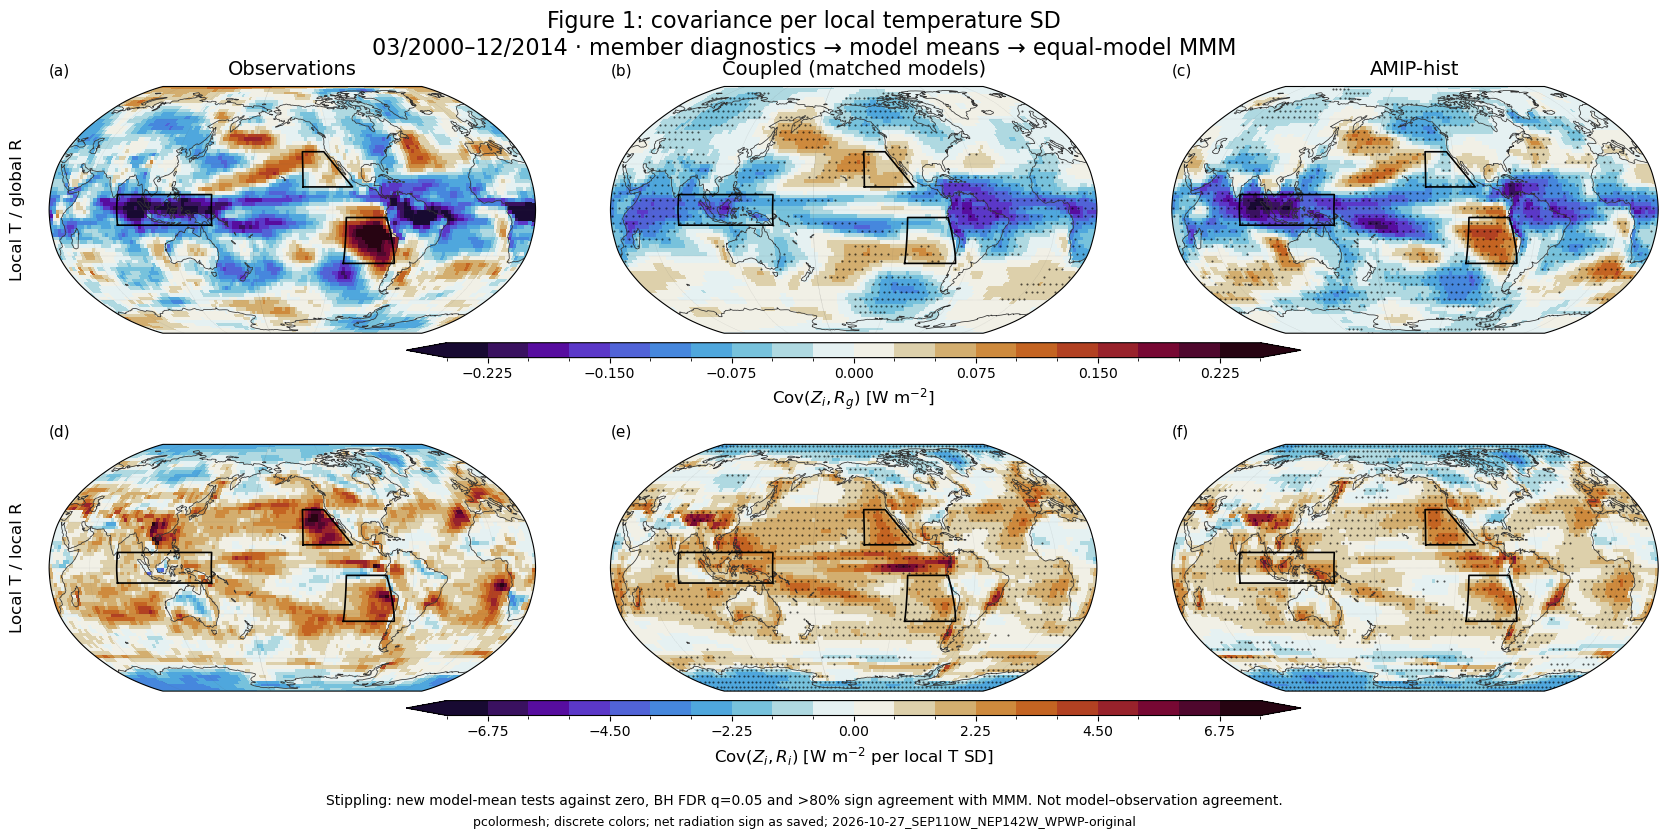

In [11]:
# 6. Recreate Figure 1 from the selected members
# The diagnostic definitions and six-panel layout match Figure 1. Updated physics
# selection, geographic outlines, and default cell rendering may change appearance.
# The original color limits (0.25, 7.5) are retained; values beyond them saturate.
figure1_keys = ['cov_Zi_R', 'cov_Zi_Ri']
diagnostic_figure_stats = {exp: {key: model_robustness(diagnostic_model_means[exp][key],
                            q=fdr_q, agreement_threshold=sign_threshold) for key in figure1_keys}
                            for exp in diagnostic_model_names}
figure1_maps = np.stack([np.stack([diagnostic_observations[key],
                                  diagnostic_MMM['historical_matched'][key], diagnostic_MMM['amip_hist'][key]])
                         for key in figure1_keys])
figure1_masks = [[None] + [diagnostic_figure_stats[exp][key]['robust']
                         for exp in ['historical_matched', 'amip_hist']] for key in figure1_keys]
figure1_path = results_dir / 'figures' / 'figure1_verified_selection.png' if save_figures else None
fig_figure1, axes_figure1, figure1_limits = plot_figure1(
    figure1_maps, ['Local T / global R', 'Local T / local R'],
    [r'Cov($Z_i,R_g$) [W m$^{-2}$]', r'Cov($Z_i,R_i$) [W m$^{-2}$ per local T SD]'],
    'Figure 1: covariance per local temperature SD', diagnostic_coordinates, diagnostic_regions,
    plot_method=plot_method, color_binning=color_binning, vlims=[0.25, 7.5], cmap=cmap_name,
    central_longitude=central_longitude, robust_masks=figure1_masks if show_stippling else None,
    show_regions=show_regions, savepath=figure1_path, overwrite=overwrite, dpi=figure_dpi)
plt.show()

In [12]:
# Scoring function — unchanged existing compare_maps
import numpy as np


def compare_maps(x, y, weights=None, *, mask=None):
    """Score one pair of aligned maps of any identical shape; return a dictionary.

    x is the target/reference; y is the comparison. Bias is y minus x, and
    amplitude ratios are y divided by x. Both maps must have the same units.
    weights are cell areas or proportional weights broadcastable to the map shape;
    None gives equal-cell weighting. mask is optional, with True meaning include.
    Masked/nonfinite data and nonpositive/nonfinite weights are excluded jointly.
    Negative finite weights raise. No valid paired cells raises.

    Coordinates are not used or aligned: put both maps on the same ordered grid
    first. Flattened, rectilinear, curvilinear, and unstructured grids all work.
    For (lat, lon) maps, latitude-only weights must be shaped (lat, 1).
    All dimensions are reduced: pass one map per call, not a stack of members.

    Spatial moments use normalized area weights, not a sample-ddof correction.
    Undefined correlations or ratios return NaN; no epsilon is added to divisors.
    lin_ccc uses these same weighted moments. Identical constant maps give NaN
    (zero denominator); unequal constants or one constant map give CCC = 0.
    """
    # Preserve masked-array exclusions, and require point-for-point matching shapes.
    # Equal shapes alone cannot verify that geographic coordinates are aligned.
    x = np.ma.asarray(x, dtype=float).filled(np.nan)
    y = np.ma.asarray(y, dtype=float).filled(np.nan)
    if x.ndim == 0 or x.shape != y.shape:
        raise ValueError("x and y must have identical, nonscalar map shapes.")
    weights = 1.0 if weights is None else weights
    weights = np.ma.asarray(weights, dtype=float).filled(np.nan)
    weights = np.broadcast_to(weights, x.shape)
    if np.any(np.isfinite(weights) & (weights < 0)):
        raise ValueError("Area weights cannot be negative.")
    include = True if mask is None else np.ma.asarray(mask, dtype=bool).filled(False)
    include = np.broadcast_to(include, x.shape)

    # Every statistic uses exactly the same paired support and renormalized weights.
    # Coverage measures retained area relative to the requested, positive-weight domain.
    support = include & np.isfinite(weights) & (weights > 0)
    valid = support & np.isfinite(x) & np.isfinite(y)
    if not valid.any():
        raise ValueError("No finite paired values with positive weights remain.")
    scaled_weights = weights[support] / weights[support].max()
    w = weights[valid] / weights[support].max()
    valid_weight_fraction = float(w.sum() / scaled_weights.sum())
    w = w / w.sum()
    xv, yv = x[valid], y[valid]

    # Spatial means and contrasts: remove each map's OWN area-weighted mean.
    # Handle exactly constant maps explicitly to avoid spurious roundoff contrast.
    mean_x = float(xv[0]) if np.all(xv == xv[0]) else float(w @ xv)
    mean_y = float(yv[0]) if np.all(yv == yv[0]) else float(w @ yv)
    xc, yc = xv - mean_x, yv - mean_y
    std_x, std_y = np.sqrt(w @ xc**2), np.sqrt(w @ yc**2)
    rms_x, rms_y = np.sqrt(w @ xv**2), np.sqrt(w @ yv**2)

    # Physical-unit discrepancies: total RMSE includes the mean offset, while
    # centered RMSE compares spatial departures from the two respective means.
    difference = yv - xv
    bias = float(w @ difference)
    rmse = float(np.sqrt(w @ difference**2))
    centered_rmse = float(np.sqrt(w @ (yc - xc)**2))

    # Correlation/contrast describe centered patterns; cosine/norm retain offsets.
    # A tiny positive denominator is not masked automatically: inspect std_x/rms_x.
    def ratio(numerator, denominator):
        return float(numerator / denominator) if denominator > 0 else np.nan

    covariance = float(w @ (xc * yc))
    correlation = ratio(covariance, std_x * std_y)
    cosine = ratio(w @ (xv * yv), rms_x * rms_y)
    contrast_ratio, norm_ratio = ratio(std_y, std_x), ratio(rms_y, rms_x)

    # Lin's CCC measures agreement with y=x, penalizing both mean and contrast
    # differences as well as imperfect correlation. Use covariance directly so
    # a constant map can give zero CCC even though Pearson correlation is undefined.
    ccc_denominator = std_x**2 + std_y**2 + (mean_y - mean_x)**2
    lin_ccc = ratio(2 * covariance, ccc_denominator)

    # Keep physical and reference-normalized errors under distinct names.
    # The weighted RMS ratio equals the weighted L2-norm ratio on common support.
    return {
        "rmse": rmse, "bias": bias, "centered_rmse": centered_rmse,
        "pattern_correlation": float(np.clip(correlation, -1, 1)),
        "contrast_ratio": contrast_ratio, "norm_ratio": norm_ratio,
        "cosine": float(np.clip(cosine, -1, 1)),
        "lin_ccc": float(np.clip(lin_ccc, -1, 1)),
        "rmse_over_rms_x": ratio(rmse, rms_x), "bias_over_rms_x": ratio(bias, rms_x),
        "rmse_over_std_x": ratio(rmse, std_x), "bias_over_std_x": ratio(bias, std_x),
        "centered_rmse_over_std_x": ratio(centered_rmse, std_x),
        "mean_x": mean_x, "mean_y": mean_y,
        "std_x": float(std_x), "std_y": float(std_y),
        "rms_x": float(rms_x), "rms_y": float(rms_y),
        "n_valid": int(valid.sum()), "valid_weight_fraction": valid_weight_fraction,
    }

In [15]:
# 7. Fix the scoring domain and score members, model means, and MMMs separately
# One FIXED spatial mask is used for both diagnostics, both experiments, every
# member, and observations. It starts from saved support and positive area weights.
# Correlation-undefined members with constant global R do not erase the whole mask;
# their correlation scores remain NaN and their covariance can still be zero.
scored_quantities = ['corr_Ti_R', 'cov_Zi_R', 'sigma_Ti']
score_mask = local_support & (base_weights > 0)
for key in scored_quantities:
    score_mask &= np.isfinite(diagnostic_observations[key])
for experiment, models in diagnostic_model_names.items():
    for model in models:
        for key in scored_quantities:
            values = diagnostic_member_values[experiment][key][model]
            if key == 'corr_Ti_R':
                values = values[diagnostic_member_values[experiment]['sigma_R'][model] > 0]
            if len(values):
                score_mask &= np.isfinite(values).all(axis=0)
if score_mask.sum() < 2:
    raise ValueError('Fewer than two common scoring cells remain. Inspect missingness before changing the domain.')
score_area_fraction = float(base_weights[score_mask].sum() / base_weights[local_support].sum())
print(f'Common scoring domain: {score_mask.sum()} cells, {score_area_fraction:.2%} of saved local-domain area.')
diagnostic_coordinates['score_mask'] = score_mask.copy()
diagnostic_metadata.update(scored_quantities=scored_quantities, score_area_fraction=score_area_fraction,
                           score_moments='Normalized spatial area weights; ddof=0',
                           score_support='Fixed across selected members, models, experiments, and diagnostics',
                           robustness={'q': fdr_q, 'agreement_threshold': sign_threshold})

def score_one_map(observation, model_map):
    """Keep undefined fields as NaN scores, with explicit zero coverage."""
    if not np.any(score_mask & np.isfinite(observation) & np.isfinite(model_map)):
        empty = {key: np.nan for key in compare_maps(np.array([0., 1.]), np.array([0., 1.]))}
        empty.update(n_valid=0, valid_weight_fraction=0.)
        return empty
    return compare_maps(observation, model_map, weights=base_weights, mask=score_mask)

diagnostic_member_scores, diagnostic_mean_member_scores = {}, {}
diagnostic_model_mean_scores, diagnostic_MMM_scores, diagnostic_MMM_mean_member_scores = {}, {}, {}
diagnostic_mean_member_score_n_valid, diagnostic_MMM_mean_member_score_n_valid = {}, {}
score_rows, invariance_rows, amplitude_rows = [], [], []
for experiment, models in diagnostic_model_names.items():
    for container in [diagnostic_member_scores, diagnostic_mean_member_scores, diagnostic_model_mean_scores,
                      diagnostic_MMM_scores, diagnostic_MMM_mean_member_scores,
                      diagnostic_mean_member_score_n_valid, diagnostic_MMM_mean_member_score_n_valid]:
        container[experiment] = {}
    for quantity in scored_quantities:
        for container in [diagnostic_member_scores, diagnostic_mean_member_scores,
                          diagnostic_model_mean_scores, diagnostic_mean_member_score_n_valid]:
            container[experiment][quantity] = {}
        for model_index, model in enumerate(models):
            results = [score_one_map(diagnostic_observations[quantity], value)
                       for value in diagnostic_member_values[experiment][quantity][model]]
            arrays = {key: np.array([result[key] for result in results]) for key in results[0]}
            diagnostic_member_scores[experiment][quantity][model] = arrays
            diagnostic_mean_member_scores[experiment][quantity][model] = {}
            diagnostic_mean_member_score_n_valid[experiment][quantity][model] = {}
            for key, array in arrays.items():
                mean, count = mean_and_count(array)
                diagnostic_mean_member_scores[experiment][quantity][model][key] = float(mean)
                diagnostic_mean_member_score_n_valid[experiment][quantity][model][key] = int(count)
            diagnostic_model_mean_scores[experiment][quantity][model] = score_one_map(
                diagnostic_observations[quantity], diagnostic_model_means[experiment][quantity][model_index])
            for member_index, member in enumerate(diagnostic_member_ids[experiment][model]):
                score_rows.append({'experiment': experiment, 'quantity': quantity, 'model': model, 'member': member,
                                   **{key: value[member_index] for key, value in arrays.items()}})
        diagnostic_MMM_scores[experiment][quantity] = score_one_map(diagnostic_observations[quantity], diagnostic_MMM[experiment][quantity])
        diagnostic_MMM_mean_member_scores[experiment][quantity] = {}
        diagnostic_MMM_mean_member_score_n_valid[experiment][quantity] = {}
        for key in arrays:
            model_scores = np.array([diagnostic_mean_member_scores[experiment][quantity][model][key] for model in models])
            mean, count = mean_and_count(model_scores)
            diagnostic_MMM_mean_member_scores[experiment][quantity][key] = float(mean)
            diagnostic_MMM_mean_member_score_n_valid[experiment][quantity][key] = int(count)

    # Positive global SD scales both the model and observation maps by positive
    # scalars. Spatial Pearson correlation must therefore remain unchanged.
    for model in models:
        correlation_scores = diagnostic_member_scores[experiment]['corr_Ti_R'][model]['pattern_correlation']
        covariance_scores = diagnostic_member_scores[experiment]['cov_Zi_R'][model]['pattern_correlation']
        for index, member in enumerate(diagnostic_member_ids[experiment][model]):
            valid = np.isfinite(correlation_scores[index]) and np.isfinite(covariance_scores[index])
            error = abs(correlation_scores[index] - covariance_scores[index]) if valid else np.nan
            if valid:
                np.testing.assert_allclose(correlation_scores[index], covariance_scores[index], atol=2e-6, rtol=2e-6)
            invariance_rows.append({'experiment': experiment, 'model': model, 'member': member,
                                    'checked': valid, 'absolute_difference': error})
            sR = float(diagnostic_member_values[experiment]['sigma_R'][model][index])
            sT = float(diagnostic_member_values[experiment]['sigma_T'][model][index])
            obs_sR, obs_sT = [float(diagnostic_observations[key]) for key in ['sigma_R', 'sigma_T']]
            amplitude_rows.append({'experiment': experiment, 'model': model, 'member': member,
                                   'sigma_R': sR, 'sigma_R_ratio': sR/obs_sR if obs_sR > 0 else np.nan,
                                   'sigma_T': sT, 'sigma_T_ratio': sT/obs_sT if obs_sT > 0 else np.nan})
member_score_table = pd.DataFrame(score_rows)
invariance_table, amplitude_table = pd.DataFrame(invariance_rows), pd.DataFrame(amplitude_rows)
print('Maximum checked pattern-correlation difference:', invariance_table['absolute_difference'].max())
print('Unchecked/undefined comparisons:', int((~invariance_table['checked']).sum()))

Common scoring domain: 10368 cells, 100.00% of saved local-domain area.
Maximum checked pattern-correlation difference: 3.3306690738754696e-16
Unchecked/undefined comparisons: 0


In [16]:
# 8. Inspect model-level changes and equal-model summaries
# Match by MODEL, never by AMIP/historical realization number. Paired aggregate
# differences use models with a finite score in BOTH experiments for that metric.
# Positive AMIP-minus-historical is better for pattern correlation/CCC; negative
# is better for RMSE. Bias/contrast changes alone do not say "better".
score_keys_to_show = ['pattern_correlation', 'rmse', 'centered_rmse', 'bias', 'contrast_ratio', 'lin_ccc']
model_rows, paired_rows, equal_model_rows = [], [], []
for quantity in diagnostic_metadata['scored_quantities']:
    for metric in score_keys_to_show:
        differences = []
        for model in diagnostic_model_names['amip_hist']:
            historical = diagnostic_mean_member_scores['historical_matched'][quantity][model][metric]
            amip = diagnostic_mean_member_scores['amip_hist'][quantity][model][metric]
            finite_pair = np.isfinite(historical) and np.isfinite(amip)
            difference = amip - historical if finite_pair else np.nan
            paired_rows.append({'quantity': quantity, 'metric': metric, 'model': model,
                                'historical': historical, 'amip': amip, 'amip_minus_historical': difference})
            if finite_pair:
                differences.append(difference)
        equal_model_rows.append({'quantity': quantity, 'metric': metric, 'n_paired_models': len(differences),
                                 'amip_minus_historical': float(np.mean(differences)) if differences else np.nan})
    for experiment, models in diagnostic_model_names.items():
        for model in models:
            model_rows.append({'experiment': experiment, 'quantity': quantity, 'model': model,
                               **diagnostic_mean_member_scores[experiment][quantity][model]})
model_score_table, paired_change_table = pd.DataFrame(model_rows), pd.DataFrame(paired_rows)
equal_model_change_table = pd.DataFrame(equal_model_rows)
amplitude_model_table = amplitude_table.groupby(['experiment', 'model'], sort=False)[
    ['sigma_R', 'sigma_R_ratio', 'sigma_T', 'sigma_T_ratio']].mean().reset_index()
paired_model_summary = pd.DataFrame(index=diagnostic_model_names['amip_hist'])
paired_model_summary.index.name = 'model'
for experiment in ['historical_matched', 'amip_hist']:
    indexed = amplitude_model_table[amplitude_model_table.experiment == experiment].set_index('model')
    paired_model_summary[experiment + '_sigma_R_ratio'] = indexed['sigma_R_ratio']
for quantity, metric, label in [('corr_Ti_R', 'pattern_correlation', 'delta_pattern_correlation'),
                                 ('corr_Ti_R', 'rmse', 'delta_correlation_map_RMSE'),
                                 ('cov_Zi_R', 'rmse', 'delta_covariance_map_RMSE'),
                                 ('sigma_Ti', 'rmse', 'delta_temperature_SD_map_RMSE')]:
    rows = paired_change_table[(paired_change_table.quantity == quantity) & (paired_change_table.metric == metric)]
    paired_model_summary[label] = rows.set_index('model')['amip_minus_historical']
paired_model_summary = paired_model_summary.reset_index()
print('Each model: radiation-SD ratios and AMIP-minus-historical score changes')
display(paired_model_summary)
print('Mean member performance: paired-model AMIP minus historical changes')
display(equal_model_change_table)
print('Global-series SDs: arithmetic means of individual-member SDs, not SDs of ensemble-mean series')
display(amplitude_model_table)
print('Separate quantities: equal-model MEAN MEMBER score versus score OF the MMM map')
display(pd.DataFrame([{'experiment': exp, 'quantity': quantity,
                      'mean_member_pattern_correlation': diagnostic_MMM_mean_member_scores[exp][quantity]['pattern_correlation'],
                      'MMM_map_pattern_correlation': diagnostic_MMM_scores[exp][quantity]['pattern_correlation'],
                      'mean_member_rmse': diagnostic_MMM_mean_member_scores[exp][quantity]['rmse'],
                      'MMM_map_rmse': diagnostic_MMM_scores[exp][quantity]['rmse']}
                     for exp in diagnostic_model_names for quantity in ['corr_Ti_R', 'cov_Zi_R']]))

Each model: radiation-SD ratios and AMIP-minus-historical score changes


,model,historical_matched_sigma_R_ratio,amip_hist_sigma_R_ratio,delta_pattern_correlation,delta_correlation_map_RMSE,delta_covariance_map_RMSE,delta_temperature_SD_map_RMSE
0,BCC-CSM2-MR,1.008420,1.101239,0.327641,-0.055755,-0.033159,-0.090381
1,CAMS-CSM1-0,1.421566,1.249569,0.203951,-0.042605,-0.046269,-0.074557
2,CESM2,1.563035,1.435107,0.107789,-0.023470,-0.032011,-0.043271
3,CIESM,0.834119,0.873584,0.234219,-0.033715,-0.016314,-0.028271
4,CNRM-CM6-1,0.690010,0.723192,0.187736,-0.014316,-0.011816,-0.037837
5,CNRM-CM6-1-HR,0.555540,0.689746,0.157452,0.004997,-0.007261,-0.022669
6,CNRM-ESM2-1,0.745041,0.781149,0.270682,-0.032915,-0.020800,-0.036891
7,CanESM5,0.855195,0.925782,0.414025,-0.041721,-0.024197,-0.078950
8,FGOALS-f3-L,0.999717,0.914112,0.105343,-0.067680,-0.047813,-0.066808
9,FGOALS-g3,0.707969,0.761240,0.153761,-0.031145,-0.012225,-0.053594


Mean member performance: paired-model AMIP minus historical changes


,quantity,metric,n_paired_models,amip_minus_historical
0,corr_Ti_R,pattern_correlation,16,0.241917
1,corr_Ti_R,rmse,16,-0.037794
2,corr_Ti_R,centered_rmse,16,-0.035294
3,corr_Ti_R,bias,16,-0.010409
4,corr_Ti_R,contrast_ratio,16,-0.039296
5,corr_Ti_R,lin_ccc,16,0.249406
6,cov_Zi_R,pattern_correlation,16,0.241917
7,cov_Zi_R,rmse,16,-0.024778
8,cov_Zi_R,centered_rmse,16,-0.022571
9,cov_Zi_R,bias,16,-0.005784


Global-series SDs: arithmetic means of individual-member SDs, not SDs of ensemble-mean series


,experiment,model,sigma_R,sigma_R_ratio,sigma_T,sigma_T_ratio
0,historical_matched,BCC-CSM2-MR,0.637288,1.008420,0.129416,1.138792
1,historical_matched,CAMS-CSM1-0,0.898383,1.421566,0.144166,1.268585
2,historical_matched,CESM2,0.987787,1.563035,0.150448,1.323862
3,historical_matched,CIESM,0.527136,0.834119,0.131011,1.152827
4,historical_matched,CNRM-CM6-1,0.436064,0.690010,0.128950,1.134692
5,historical_matched,CNRM-CM6-1-HR,0.351083,0.555540,0.086200,0.758513
6,historical_matched,CNRM-ESM2-1,0.470841,0.745041,0.127686,1.123571
7,historical_matched,CanESM5,0.540455,0.855195,0.145043,1.276296
8,historical_matched,FGOALS-f3-L,0.631789,0.999717,0.169823,1.494351
9,historical_matched,FGOALS-g3,0.447413,0.707969,0.133376,1.173636


Separate quantities: equal-model MEAN MEMBER score versus score OF the MMM map


,experiment,quantity,mean_member_pattern_correlation,MMM_map_pattern_correlation,mean_member_rmse,MMM_map_rmse
0,historical_matched,corr_Ti_R,0.342944,0.607837,0.161858,0.102239
1,historical_matched,cov_Zi_R,0.342944,0.608347,0.105887,0.064725
2,amip_hist,corr_Ti_R,0.584861,0.778828,0.124064,0.080526
3,amip_hist,cov_Zi_R,0.584861,0.781280,0.081110,0.050609


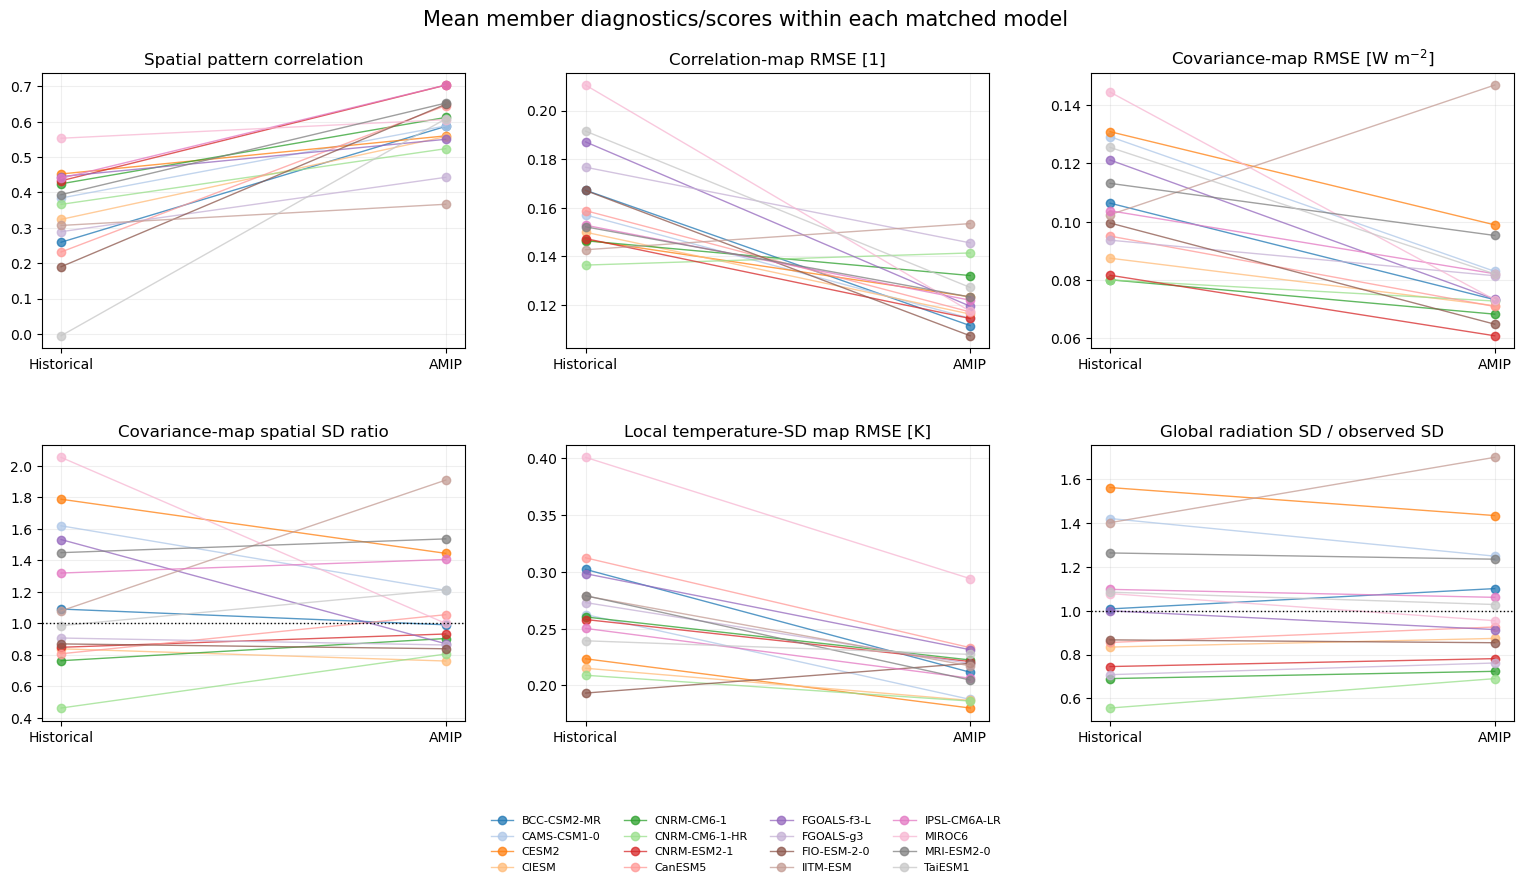

In [17]:
# 9. Plot the main comparisons, with one line per matched model
# Correlation-field RMSE retains errors in the spatial mean and scale of temporal
# correlation coefficients. Spatial pattern correlation alone removes both.
panels = [('corr_Ti_R', 'pattern_correlation', 'Spatial pattern correlation'),
          ('corr_Ti_R', 'rmse', 'Correlation-map RMSE [1]'),
          ('cov_Zi_R', 'rmse', r'Covariance-map RMSE [W m$^{-2}$]'),
          ('cov_Zi_R', 'contrast_ratio', 'Covariance-map spatial SD ratio'),
          ('sigma_Ti', 'rmse', 'Local temperature-SD map RMSE [K]')]
fig_comparisons, axes_comparisons = plt.subplots(2, 3, figsize=(16, 9))
fig_comparisons.subplots_adjust(left=0.06, right=0.98, bottom=0.19, top=0.91, hspace=0.35, wspace=0.24)
model_colors = {model: plt.get_cmap('tab20')(index % 20) for index, model in enumerate(diagnostic_model_names['amip_hist'])}
for ax, (quantity, metric, title) in zip(axes_comparisons.flat, panels):
    subset = paired_change_table[(paired_change_table.quantity == quantity) & (paired_change_table.metric == metric)]
    for _, row in subset.iterrows():
        ax.plot([0, 1], [row.historical, row.amip], marker='o', alpha=0.75, linewidth=1,
                color=model_colors[row.model], label=row.model)
    if metric == 'contrast_ratio':
        ax.axhline(1., color='black', linestyle=':', linewidth=1)
    ax.set_xticks([0, 1], ['Historical', 'AMIP'])
    ax.set_title(title)
    ax.grid(alpha=0.2)
ax = axes_comparisons.flat[-1]
for model in diagnostic_model_names['amip_hist']:
    rows = amplitude_model_table[amplitude_model_table.model == model].set_index('experiment')
    ax.plot([0, 1], rows.loc[['historical_matched', 'amip_hist'], 'sigma_R_ratio'], marker='o',
            color=model_colors[model], alpha=0.75, linewidth=1)
ax.axhline(1., color='black', linestyle=':', linewidth=1)
ax.set_xticks([0, 1], ['Historical', 'AMIP'])
ax.set_title('Global radiation SD / observed SD')
ax.grid(alpha=0.2)
fig_comparisons.suptitle('Mean member diagnostics/scores within each matched model', fontsize=15)
handles, labels = axes_comparisons.flat[0].get_legend_handles_labels()
fig_comparisons.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, 0.01), ncol=4,
                       frameon=False, fontsize=8)
if save_figures:
    comparison_path = results_dir / 'figures' / 'member_first_comparisons.png'
    if comparison_path.exists() and not overwrite:
        raise FileExistsError(comparison_path)
    comparison_path.parent.mkdir(parents=True, exist_ok=True)
    fig_comparisons.savefig(comparison_path, dpi=figure_dpi, bbox_inches='tight')
plt.show()